In [ ]:
pip install torch pandas numpy scikit-learn matplotlib seaborn tqdm

In [1]:
pip install lime


Note: you may need to restart the kernel to use updated packages.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader , WeightedRandomSampler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report, f1_score
from tqdm import tqdm
# Set seeds
np.random.seed(42)
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

#%% [markdown]
# ## 1. Configuration and Attack Mapping

#%%
CONFIG = {
    'batch_size': 512,
    'epochs': 30,
    'learning_rate': 0.001,
    'input_shape': (115, 1), # (Features, Channels)
    'use_mock_data': False, # Set to False and provide path below for real data
    # 'dataset_path': '/kaggle/input/CICIOT23/',
    'dataset_paths':["/kaggle/input/nbaiot-dataset/1.benign.csv","/kaggle/input/nbaiot-dataset/1.gafgyt.combo.csv"
,"/kaggle/input/nbaiot-dataset/1.gafgyt.junk.csv",
"/kaggle/input/nbaiot-dataset/1.gafgyt.tcp.csv",
"/kaggle/input/nbaiot-dataset/1.mirai.udp.csv",
"/kaggle/input/nbaiot-dataset/1.mirai.scan.csv",
"/kaggle/input/nbaiot-dataset/1.mirai.syn.csv",
"/kaggle/input/nbaiot-dataset/1.mirai.udpplain.csv"
,"/kaggle/input/nbaiot-dataset/1.mirai.ack.csv"],
    "labels": [
        "benign",
        "Gafgyt_Combo",
        "Gafgyt_Junk",
        "Gafgyt_TCP",
        "Mirai_UDP",
        "Mirai_Scan",
        "Mirai_SYN",
        "Mirai_UDPPlain",
        "Mirai_ACK"
    ],
    "temperature":2.0,
    'ae_loss_weight': 0.1 
}

# --- Detailed Mapping Strategy (From User Request) ---

ATTACK_MAPPING = {
   'normal':"Normal",
    "injection":"Injection",
    "scanning":"Scanning",
    "password":"Password",
    "ransomware":"Ransomware",
    'xss':"XSS",
    'backdoor':"Backdoor",
    'dos':"Dos",
    'ddos':"DDos",
    'mitm':'Mitm'
}


Using device: cuda


In [2]:
full_data=pd.DataFrame()
for i,j in enumerate(CONFIG["dataset_paths"]):
    df1=pd.read_csv(j)
    df2=pd.read_csv(j.replace("1","2"))
    df1["label"]=CONFIG["labels"][i]
    df2["label"]=CONFIG["labels"][i]
    df=pd.concat([df1,df2], ignore_index=True)
    full_data=pd.concat([full_data,df], ignore_index=True)
    

In [3]:
full_data.size

183995256

In [4]:
full_data["label"].value_counts().keys()

Index(['Mirai_UDP', 'Mirai_SYN', 'Mirai_ACK', 'Gafgyt_TCP', 'Mirai_UDPPlain',
       'Mirai_Scan', 'Gafgyt_Combo', 'benign', 'Gafgyt_Junk'],
      dtype='object', name='label')

In [5]:

SEEN_CLASSES = ['Mirai_UDP', 'Mirai_SYN', 'Mirai_ACK', 'Gafgyt_TCP',
        'Gafgyt_Combo', 'benign','Gafgyt_Junk','Mirai_UDPPlain']
UNSEEN_CLASSES = ['Mirai_Scan']

print(f"Training on: {SEEN_CLASSES}")
print(f"Testing detection of: {UNSEEN_CLASSES}")

Training on: ['Mirai_UDP', 'Mirai_SYN', 'Mirai_ACK', 'Gafgyt_TCP', 'Gafgyt_Combo', 'benign', 'Gafgyt_Junk', 'Mirai_UDPPlain']
Testing detection of: ['Mirai_Scan']


In [6]:
    CONFIG

{'batch_size': 512,
 'epochs': 30,
 'learning_rate': 0.001,
 'input_shape': (115, 1),
 'use_mock_data': False,
 'dataset_paths': ['/kaggle/input/nbaiot-dataset/1.benign.csv',
  '/kaggle/input/nbaiot-dataset/1.gafgyt.combo.csv',
  '/kaggle/input/nbaiot-dataset/1.gafgyt.junk.csv',
  '/kaggle/input/nbaiot-dataset/1.gafgyt.tcp.csv',
  '/kaggle/input/nbaiot-dataset/1.mirai.udp.csv',
  '/kaggle/input/nbaiot-dataset/1.mirai.scan.csv',
  '/kaggle/input/nbaiot-dataset/1.mirai.syn.csv',
  '/kaggle/input/nbaiot-dataset/1.mirai.udpplain.csv',
  '/kaggle/input/nbaiot-dataset/1.mirai.ack.csv'],
 'labels': ['benign',
  'Gafgyt_Combo',
  'Gafgyt_Junk',
  'Gafgyt_TCP',
  'Mirai_UDP',
  'Mirai_Scan',
  'Mirai_SYN',
  'Mirai_UDPPlain',
  'Mirai_ACK'],
 'temperature': 2.0,
 'ae_loss_weight': 0.1}

In [7]:
class IoTDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
        
    def __len__(self):
        return len(self.X)
    
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


In [8]:
config=CONFIG

In [9]:
# add the balance of the classes in the training of the data 

In [10]:


def load_and_process(config):
    try:
        
        X = full_data.drop(['label'], axis=1).values
        y = full_data['label'].values
        # Scale
        scaler = StandardScaler()
        X = scaler.fit_transform(X)
        # Reshape for Sequence: (Samples, Features, 1) -> PyTorch will need (Batch, Channels, Length) later
        X = X.reshape(X.shape[0], X.shape[1], 1)
    
        return X, y, full_data['label'].values


    except FileNotFoundError:
        print(f"File not found at {config['dataset_path']}. Check path.")
        return None, None, None
    except Exception as e:
        print(f"An error occurred: {e}")
        return None, None, None

X, y, y_raw = load_and_process(CONFIG)

#%% [markdown]
# ## 3. Splitting: Training (Seen Only) vs Testing (Mixed)

#%%
seen_indices = np.isin(y, SEEN_CLASSES)
unseen_indices = ~seen_indices

X_seen = X[seen_indices]
y_seen = y[seen_indices]

le = LabelEncoder()
y_seen_enc = le.fit_transform(y_seen)
num_classes = len(le.classes_)

X_train, X_temp, y_train, y_temp = train_test_split(X_seen, y_seen_enc, test_size=0.3, random_state=42, stratify=y_seen_enc)
X_val, X_test_seen, y_val, y_test_seen = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

X_unseen = X[unseen_indices]
y_unseen = y[unseen_indices]

y_test_seen_str = le.inverse_transform(y_test_seen)
X_test_final = np.concatenate([X_test_seen, X_unseen])
y_test_final_str = np.concatenate([y_test_seen_str, y_unseen])

y_train_tensor = y_train
y_val_tensor = y_val
y_test_dummy = np.zeros(len(X_test_final))

train_dataset = IoTDataset(X_train, y_train_tensor)
val_dataset = IoTDataset(X_val, y_val_tensor)
test_dataset = IoTDataset(X_test_final, y_test_dummy)

# --- WeightedRandomSampler Implementation ---
print("\nPreparing WeightedRandomSampler...")
# 1. Compute weight for each class: w_j = 1 / count_j
# Note: We use the same logic as compute_class_weight but manually to map to samples
class_counts = np.bincount(y_train)
class_weights_val = 1. / class_counts
# 2. Assign weight to each sample
sample_weights = class_weights_val[y_train]
# 3. Create Sampler
sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

# OPTIMIZATION: sampler added, shuffle must be False
train_loader = DataLoader(train_dataset, batch_size=CONFIG['batch_size'], sampler=sampler, shuffle=False, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=CONFIG['batch_size'], shuffle=False, num_workers=4, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=CONFIG['batch_size'], shuffle=False, num_workers=4, pin_memory=True)

print(f"Training Samples: {len(X_train)}")
print(f"Validation Samples: {len(X_val)}")
print(f"Test Samples (Total): {len(X_test_final)}")



Preparing WeightedRandomSampler...
Training Samples: 1004702
Validation Samples: 215293
Test Samples (Total): 366171


In [11]:
len(X_unseen)


150877

In [12]:
class CNNTransformerBiLSTM(nn.Module):
    def __init__(self, input_len, num_classes):
        super(CNNTransformerBiLSTM, self).__init__()
        
        # 1. CNN Layers (Spatial Features)
        # Input shape: (Batch, 1, Features)
        self.conv1 = nn.Conv1d(in_channels=1, out_channels=64, kernel_size=3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool1d(kernel_size=2) 
        self.conv2 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        
        # 2. Transformer Layer (Contextual Features)
        encoder_layer = nn.TransformerEncoderLayer(d_model=128, nhead=4, dim_feedforward=128, dropout=0.1, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=1)
        
        # 3. BiLSTM Layer (Temporal Features - Replaces paper's RNN)
        # Input size is 128 from Transformer
        self.lstm = nn.LSTM(input_size=128, hidden_size=64, bidirectional=True, batch_first=True)
        
        # 4. Classifier
        # Input = 64 * 2 (Bidirectional)
        self.fc1 = nn.Linear(64*2, 64)
        self.dropout = nn.Dropout(0.3)
        self.fc_out = nn.Linear(64, num_classes)
        
    def forward(self, x):
        x = x.permute(0, 2, 1) 
        
        # --- CNN Block ---
        x = self.relu(self.conv1(x))
        x = self.pool(x)
        x = self.relu(self.conv2(x)) 
        
        # --- Transformer Block ---
        # Transformer expects (Batch, Sequence Length, Features/Channels)
        x = x.permute(0, 2, 1) 
        x = self.transformer(x)
        
        # --- BiLSTM Block ---
        # LSTM expects (Batch, Sequence Length, Features) which matches current x
        _, (h_n, _) = self.lstm(x)
        x = torch.cat((h_n[-2,:,:], h_n[-1,:,:]), dim=1) # (Batch, 128)
        
        # --- Classifier ---
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc_out(x)
        
        return x



In [50]:
# Initialize Model
INPUT_DIM = CONFIG['input_shape'][0]
model = CNNTransformerBiLSTM(INPUT_DIM, num_classes).to(device)

# Losses
criterion = nn.CrossEntropyLoss(label_smoothing=0.1) 
optimizer = optim.Adam(model.parameters(), lr=CONFIG['learning_rate'], weight_decay=1e-4)


In [51]:
def train_model(model, train_loader, val_loader, epochs, save_path='gtrs_best_model.pth'):
    history = {'accuracy': [], 'val_accuracy': [], 'loss': [], 'val_loss': []}
    best_val_acc = 0.0
    
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0
        
        train_loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}", leave=True)
        
        for inputs, labels in train_loop:
            inputs, labels = inputs.to(device), labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            
            train_loop.set_postfix(loss=loss.item(), acc=correct/total)
            
        epoch_acc = correct / total
        epoch_loss = running_loss / len(train_loader)
        
        # Validation
        model.eval()
        val_loss = 0.0
        val_correct = 0
        val_total = 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item()
                _, predicted = torch.max(outputs.data, 1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()
                
        val_acc = val_correct / val_total
        val_loss_avg = val_loss / len(val_loader)
        
        history['accuracy'].append(epoch_acc)
        history['loss'].append(epoch_loss)
        history['val_accuracy'].append(val_acc)
        history['val_loss'].append(val_loss_avg)
        
        # --- Save Best Model ---
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), save_path)
            tqdm.write(f"  --> Best model saved to '{save_path}' (Val Acc: {val_acc:.4f})")
        
        print(f"Summary: Loss: {epoch_loss:.4f} | Acc: {epoch_acc:.4f} | Val Loss: {val_loss_avg:.4f} | Val Acc: {val_acc:.4f}")
    
    # Save final model
    torch.save(model.state_dict(), 'gtrs_final_model.pth')
    print("Training Complete. Final model saved to 'gtrs_final_model.pth'")
    
    return history


In [54]:
# print("Starting Training...")
# history = train_model(model, train_loader, val_loader, CONFIG['epochs'])

Starting Training...


Epoch 1/30: 100%|██████████| 1963/1963 [00:47<00:00, 41.35it/s, acc=0.982, loss=0.521]


  --> Best model saved to 'gtrs_best_model.pth' (Val Acc: 0.9961)
Summary: Loss: 0.5249 | Acc: 0.9825 | Val Loss: 0.4758 | Val Acc: 0.9961


Epoch 2/30: 100%|██████████| 1963/1963 [00:47<00:00, 41.31it/s, acc=0.99, loss=0.492] 


  --> Best model saved to 'gtrs_best_model.pth' (Val Acc: 0.9968)
Summary: Loss: 0.5120 | Acc: 0.9900 | Val Loss: 0.4741 | Val Acc: 0.9968


...

Summary: Loss: 0.4958 | Acc: 0.9971 | Val Loss: 0.4759 | Val Acc: 0.9971


Epoch 29/30: 100%|██████████| 1963/1963 [00:47<00:00, 41.39it/s, acc=0.998, loss=0.496]


Summary: Loss: 0.4930 | Acc: 0.9982 | Val Loss: 0.4705 | Val Acc: 0.9984


Epoch 30/30: 100%|██████████| 1963/1963 [00:47<00:00, 41.27it/s, acc=0.998, loss=0.488]


Summary: Loss: 0.4930 | Acc: 0.9982 | Val Loss: 0.4764 | Val Acc: 0.9970
Training Complete. Final model saved to 'gtrs_final_model.pth'


In [14]:

def get_probabilities(model, loader, device):
    model.eval()
    all_probs = []
    all_labels = []
    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            probs = torch.softmax(outputs, dim=1)
            all_probs.append(probs.cpu().numpy())
            all_labels.append(labels.numpy())
            
    return np.concatenate(all_probs), np.concatenate(all_labels)

def optimize_thresholds(probs, y_true_indices, n_classes, le, max_iter=200):
    """
    Optimizes alpha and beta thresholds using GTRS (Game Theoretic Rough Sets)
    based on the trade-off between Accuracy and Generality.
    
    Ref: Section 3.3.3 Iterative threshold learning in GTRS
    Strategy S3: Alpha decreases, Beta increases simultaneously.
    """
    thresholds = {}
    print("\n--- GTRS Threshold Optimization (Strategy S3: α↓ β↑) ---")
    
    # Constant 'c' controls the step size of the adjustment (from Eq 18/20 logic)
    # The paper implies an adaptive step, but a small fixed constant ensures stability.
    c = 0.05 

    for k in range(n_classes):
        class_name = le.inverse_transform([k])[0]
        
        # Get probabilities for GROUND TRUTH instances of this class
        # (We optimize based on how well the model captures the true class)
        idx = np.where(y_true_indices == k)[0]
        
        if len(idx) == 0:
            thresholds[k] = {'alpha': 1.0, 'beta': 0.0}
            continue
            
        probs_k = probs[idx, k]
        total_objects = len(probs_k)

        # Initial thresholds as per Paper Algorithm 2 Line 1
        alpha = 1.0
        beta = 0.0
        
        # Stop condition flags
        stop_optimization = False

        for i in range(max_iter):
            # 1. Trisecting (divide objects into regions)
            # Inside: P(x) >= alpha
            n_inside = np.sum(probs_k >= alpha)
            
            # Partial: beta < P(x) < alpha
            n_partial = np.sum((probs_k > beta) & (probs_k < alpha))
            
            # Outside: P(x) <= beta (Implicitly the rest)

            # 2. Calculate Payoffs (Eq 13 & 14)
            # Accuracy: Fraction of objects correctly placed in Inside region
            accuracy = n_inside / total_objects if total_objects > 0 else 0
            
            # Generality: Fraction of objects in Inside OR Partial regions
            # (Paper definition: Total clustered objects / Total objects)
            generality = (n_inside + n_partial) / total_objects if total_objects > 0 else 0
            
            # 3. Calculate the trade-off (Gap)
            gap = generality - accuracy

            # 4. Update Thresholds (Iterative Learning - Eq 17 & 19 adapted for S3)
            # Strategy S3: Alpha decreases, Beta increases.
            # The magnitude of change is driven by the 'gap' (G - A).
            # If G >> A, we have too many uncertain items, so we move thresholds to resolve them.
            
            # Decrease Alpha
            alpha_new = alpha - (alpha * gap * c)
            
            # Increase Beta
            # Note: We use (1 - beta) scaling or similar to ensure it grows, 
            # but strictly following the paper's update style:
            # The paper adds to beta based on the gap to shrink the partial region from the bottom.
            beta_new = beta + ((1.0 - beta) * gap * c)

            # 5. Boundary & Convergence Checks (Algorithm 2 Line 14)
            
            # Constraint: Alpha must not drop below 0.5, Beta must not rise above 0.5
            # (Or simply Alpha must always be > Beta)
            if alpha_new <= 0.5 or beta_new >= 0.5 or alpha_new <= beta_new:
                stop_optimization = True
            
            # Constraint: Convergence (Accuracy ≈ Generality)
            if abs(gap) < 0.001:
                stop_optimization = True

            if stop_optimization:
                break
                
            alpha = alpha_new
            beta = beta_new

        thresholds[k] = {'alpha': alpha, 'beta': beta}
        print(f"Class {class_name:<20} | Iter: {i:<3} | Alpha: {alpha:.4f} | Beta: {beta:.4f} | Acc: {accuracy:.4f} | Gen: {generality:.4f}")
        
    return thresholds

# --- Usage ---
# Assuming 'model', 'val_loader', 'device', 'num_classes', and 'le' (LabelEncoder) are defined
val_probs, val_labels_true = get_probabilities(model, val_loader, device)
opt_thresholds = optimize_thresholds(val_probs, val_labels_true, num_classes, le)


--- GTRS Threshold Optimization (Strategy S3: α↓ β↑) ---
Class Gafgyt_Combo         | Iter: 199 | Alpha: 0.8224 | Beta: 0.1776 | Acc: 0.9943 | Gen: 0.9996
Class Gafgyt_Junk          | Iter: 199 | Alpha: 0.8192 | Beta: 0.1808 | Acc: 0.9934 | Gen: 0.9998
Class Gafgyt_TCP           | Iter: 2   | Alpha: 0.9025 | Beta: 0.0975 | Acc: 0.9993 | Gen: 0.9998
Class Mirai_ACK            | Iter: 199 | Alpha: 0.8820 | Beta: 0.1180 | Acc: 0.9981 | Gen: 1.0000
Class Mirai_SYN            | Iter: 199 | Alpha: 0.8790 | Beta: 0.1210 | Acc: 0.9981 | Gen: 0.9999
Class Mirai_UDP            | Iter: 199 | Alpha: 0.8751 | Beta: 0.1249 | Acc: 0.9977 | Gen: 0.9999
Class Mirai_UDPPlain       | Iter: 199 | Alpha: 0.8855 | Beta: 0.1145 | Acc: 0.9986 | Gen: 0.9999
Class benign               | Iter: 199 | Alpha: 0.8661 | Beta: 0.1339 | Acc: 0.9961 | Gen: 0.9998


In [13]:
model = CNNTransformerBiLSTM(input_len=20, num_classes=num_classes).to(device)
model.load_state_dict(torch.load('gtrs_best_model.pth'))
model.eval()
print("Model loaded successfully!")

Model loaded successfully!



Running Inference on Mixed Test Set...

Classification Report:
                precision    recall  f1-score   support

      Emerging       1.00      1.00      1.00    150877
  Gafgyt_Combo       0.99      0.99      0.99     16909
   Gafgyt_Junk       1.00      0.99      1.00      8907
    Gafgyt_TCP       1.00      1.00      1.00     28075
     Mirai_ACK       1.00      1.00      1.00     32322
     Mirai_SYN       1.00      1.00      1.00     35907
     Mirai_UDP       1.00      1.00      1.00     58372
Mirai_UDPPlain       1.00      1.00      1.00     25403
        benign       1.00      1.00      1.00      9399

      accuracy                           1.00    366171
     macro avg       1.00      1.00      1.00    366171
  weighted avg       1.00      1.00      1.00    366171



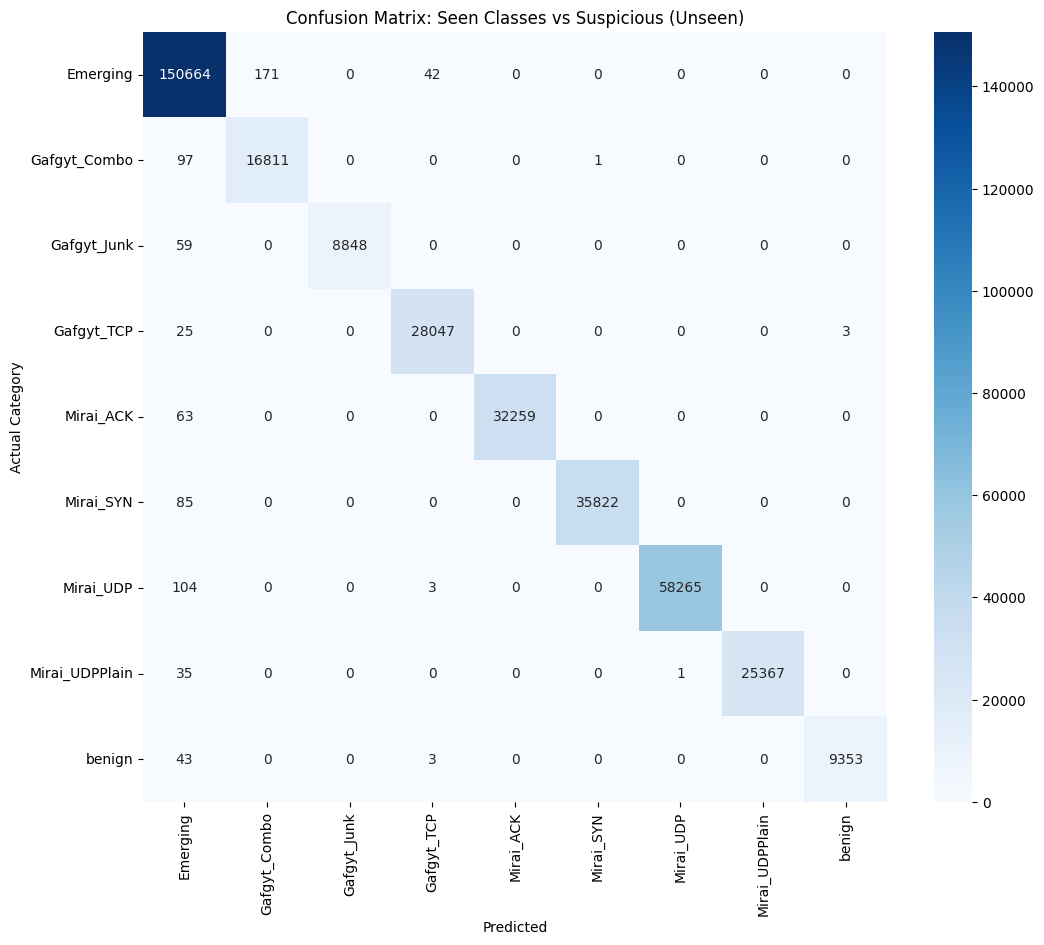


--- Detailed Analysis of Unseen Attack Detection ---


In [15]:
def predict_gtrs(model, loader, thresholds, le, temperature=1.0):
    model.eval()
    preds = []
    
    with torch.no_grad():
        for inputs, _ in loader: # Ignore dummy labels
            inputs = inputs.to(device)
            outputs = model(inputs)
            
            # SOLUTION 3: Temperature Scaling during inference
            # Divides logits by T > 1 to soften distribution
            probs_batch = torch.softmax(outputs / temperature, dim=1).cpu().numpy()
            
            for i in range(len(probs_batch)):
                p_vec = probs_batch[i]
                pred_idx = np.argmax(p_vec)
                conf = p_vec[pred_idx]
                
                t = thresholds[pred_idx]
                
                if conf >= t['alpha']:
                    preds.append(le.inverse_transform([pred_idx])[0])
                else:
                    preds.append('Emerging')
                    
    return np.array(preds)

print("\nRunning Inference on Mixed Test Set...")
y_pred = predict_gtrs(model, test_loader, opt_thresholds, le )

#%% [markdown]
# ## 8. Evaluation

y_true_mapped = []
for label in y_test_final_str:
    if label in UNSEEN_CLASSES:
        y_true_mapped.append('Emerging')
    else:
        y_true_mapped.append(label)

print("\nClassification Report:")
print(classification_report(y_true_mapped, y_pred))

# Confusion Matrix
plt.figure(figsize=(12, 10))
labels = sorted(list(set(y_true_mapped) | set(y_pred)))
cm = confusion_matrix(y_true_mapped, y_pred, labels=labels)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix: Seen Classes vs Suspicious (Unseen)")
plt.ylabel('Actual Category')
plt.xlabel('Predicted')
plt.savefig('confusion_matrix_ton_iot.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n--- Detailed Analysis of Unseen Attack Detection ---")
analysis_df = pd.DataFrame({
    'Actual_Category': y_test_final_str,
    'Prediction': y_pred
})

In [57]:
# for both the seen and unseen attacks


Running Inference on Mixed Test Set...

PART 1: PERFORMANCE ON SEEN CLASSES

Classification Report (Seen Classes):
                precision    recall  f1-score   support

      Emerging       0.00      0.00      0.00         0
  Gafgyt_Combo       1.00      0.99      1.00     16909
   Gafgyt_Junk       1.00      0.99      1.00      8907
    Gafgyt_TCP       1.00      1.00      1.00     28075
     Mirai_ACK       1.00      1.00      1.00     32322
     Mirai_SYN       1.00      1.00      1.00     35907
     Mirai_UDP       1.00      1.00      1.00     58372
Mirai_UDPPlain       1.00      1.00      1.00     25403
        benign       1.00      1.00      1.00      9399

      accuracy                           1.00    215294
     macro avg       0.89      0.89      0.89    215294
  weighted avg       1.00      1.00      1.00    215294



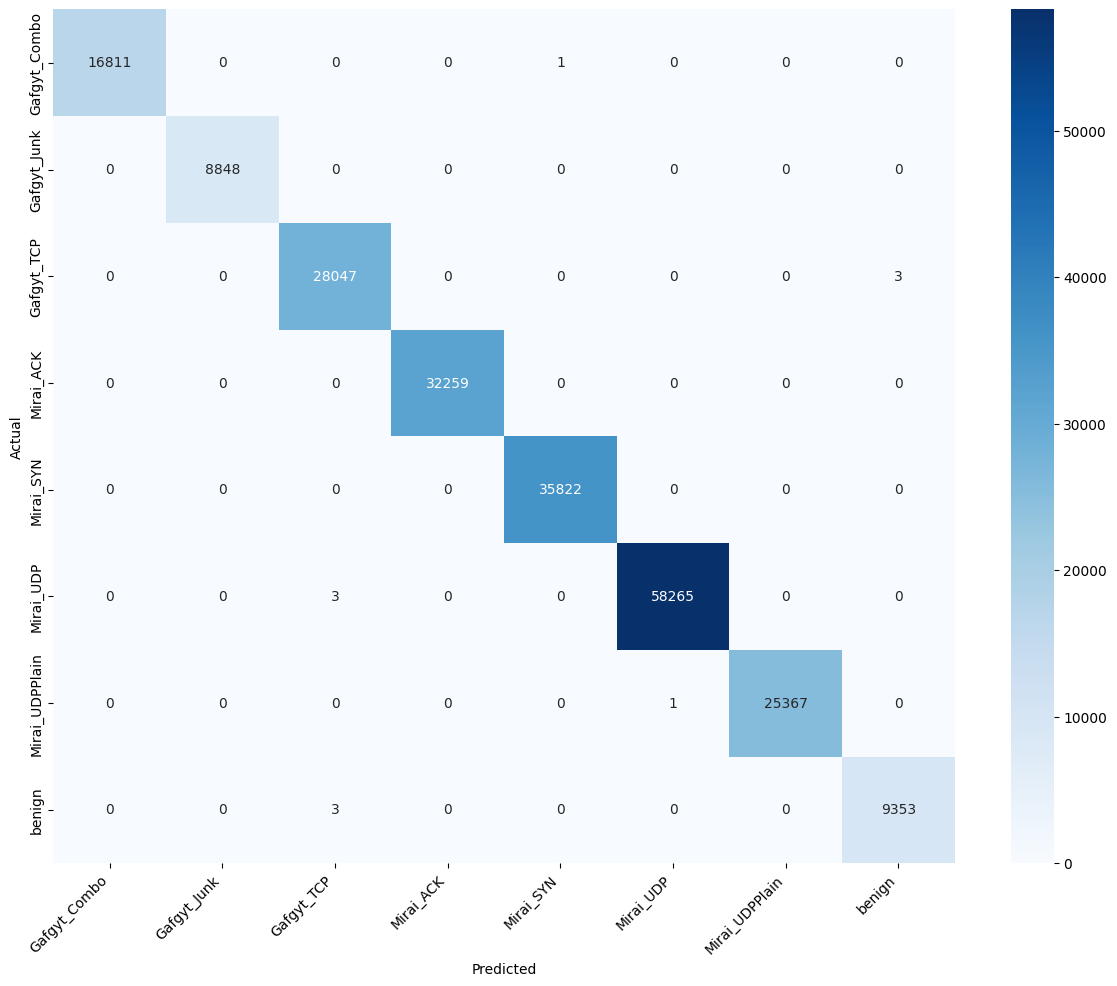


PART 2: DETECTION OF UNSEEN ATTACKS

Total Unseen Samples: 150877
Successfully Flagged as Emerging: 150664
Overall Detection Rate: 0.9986 (99.86%)

Detection Rate by Specific Unseen Attack:
Actual
Mirai_Scan    0.998588
Name: Predicted, dtype: float64


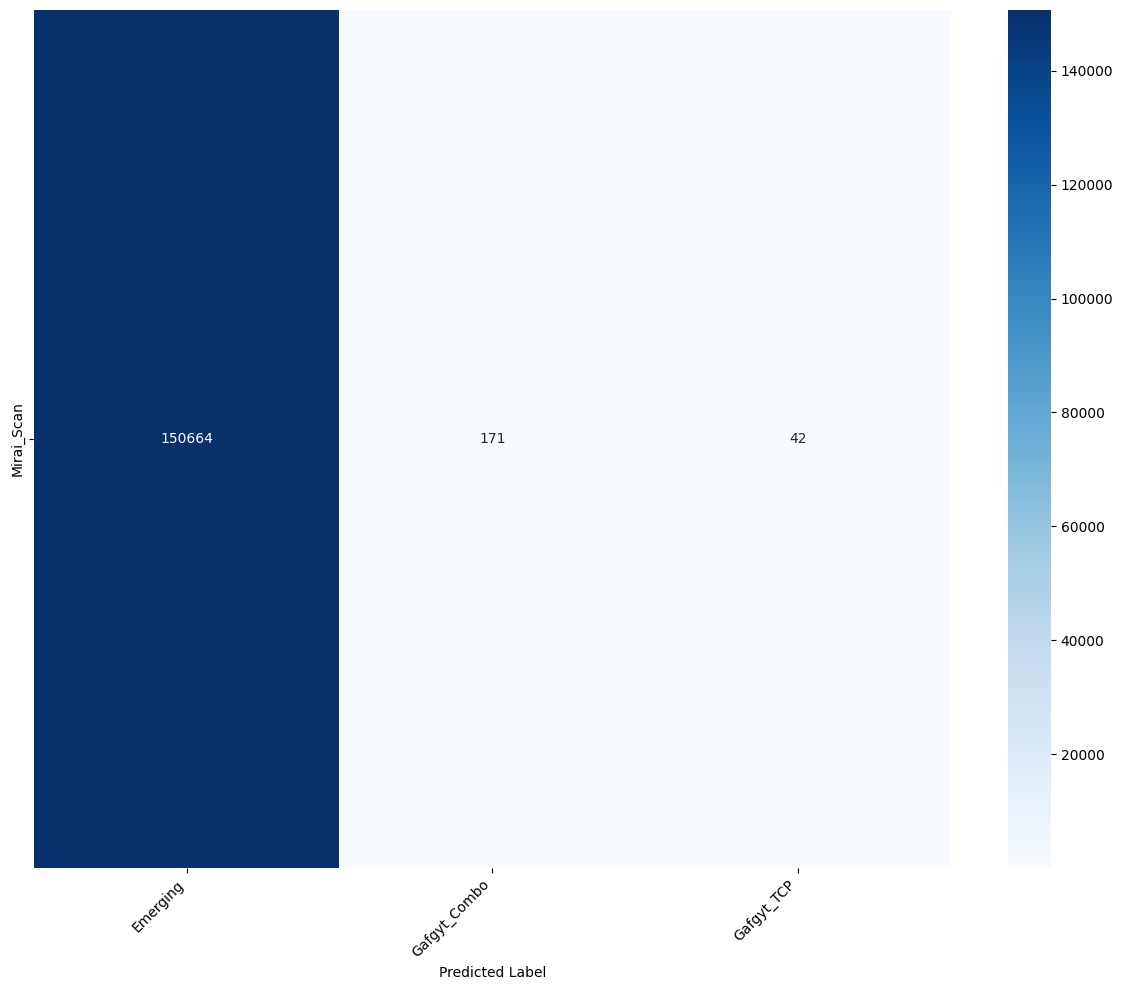

In [16]:

# --- 1. Run Inference ---
print("\nRunning Inference on Mixed Test Set...")
y_pred = predict_gtrs(model, test_loader, opt_thresholds, le, temperature=1.0)

# --- 2. Separate Data into 'Seen' vs 'Unseen' Groups ---
known_classes = set(le.classes_)

# Create mask
is_seen_mask = np.array([label in known_classes for label in y_test_final_str])

# Split
y_true_seen = np.array(y_test_final_str)[is_seen_mask]
y_pred_seen = y_pred[is_seen_mask]

y_true_unseen = np.array(y_test_final_str)[~is_seen_mask]
y_pred_unseen = y_pred[~is_seen_mask]

# ==========================================
# PART 1: SEEN CLASSES (Known Attacks)
# ==========================================
print("\n" + "="*50)
print("PART 1: PERFORMANCE ON SEEN CLASSES")
print("="*50)

if len(y_true_seen) > 0:
    print("\nClassification Report (Seen Classes):")
    # We calculate metrics normally
    print(classification_report(y_true_seen, y_pred_seen, zero_division=0))

    # --- CUSTOM MATRIX using crosstab ---
    # This is safer and easier to manipulate than confusion_matrix
    df_cm_seen = pd.crosstab(
        pd.Series(y_true_seen, name='Actual'),
        pd.Series(y_pred_seen, name='Predicted')
    )

    # USER REQUEST: Remove 'Emerging' column if it exists in Seen analysis
    if 'Emerging' in df_cm_seen.columns:
        df_cm_seen = df_cm_seen.drop(columns=['Emerging'])

    plt.figure(figsize=(12, 10))
    sns.heatmap(df_cm_seen, annot=True, fmt='d', cmap='Blues')
    plt.title("")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig("confusion_seen_baiot.png")
    plt.show()

else:
    print("No Seen samples in this test set.")

# ==========================================
# PART 2: UNSEEN ATTACKS (Unknowns)
# ==========================================
print("\n" + "="*50)
print("PART 2: DETECTION OF UNSEEN ATTACKS")
print("="*50)

if len(y_true_unseen) > 0:
    # 1. Detection Rate
    correctly_detected = np.sum(y_pred_unseen == 'Emerging')
    detection_rate = correctly_detected / len(y_true_unseen)
    
    print(f"\nTotal Unseen Samples: {len(y_true_unseen)}")
    print(f"Successfully Flagged as Emerging: {correctly_detected}")
    print(f"Overall Detection Rate: {detection_rate:.4f} ({detection_rate*100:.2f}%)")

    # 2. Detailed Breakdown (Fixing the groupby warning)
    # We select the 'Predicted' column strictly before applying logic
    analysis_df = pd.DataFrame({'Actual': y_true_unseen, 'Predicted': y_pred_unseen})
    
    print("\nDetection Rate by Specific Unseen Attack:")
    breakdown = analysis_df.groupby('Actual')['Predicted'].apply(
        lambda x: (x == 'Emerging').mean()
    )
    print(breakdown)

    # 3. Confusion Matrix via Crosstab (Fixes ValueError)
    # Rows = Actual Unseen Names, Cols = Predicted Labels
    df_cm_unseen = pd.crosstab(
        pd.Series(y_true_unseen, name=''),
        pd.Series(y_pred_unseen, name='Predicted Label')
    )

    # Reorder columns to put 'Emerging' first (for better visibility)
    cols = list(df_cm_unseen.columns)
    if 'Emerging' in cols:
        cols.remove('Emerging')
        cols.insert(0, 'Emerging')
        df_cm_unseen = df_cm_unseen[cols]

    plt.figure(figsize=(12, 10))
    sns.heatmap(df_cm_unseen, annot=True, fmt='d', cmap='Blues')
    plt.title("")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig("confusion_unseen_baiot.png")
    plt.show()

else:
    print("No Unseen samples in this test set.")

unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.


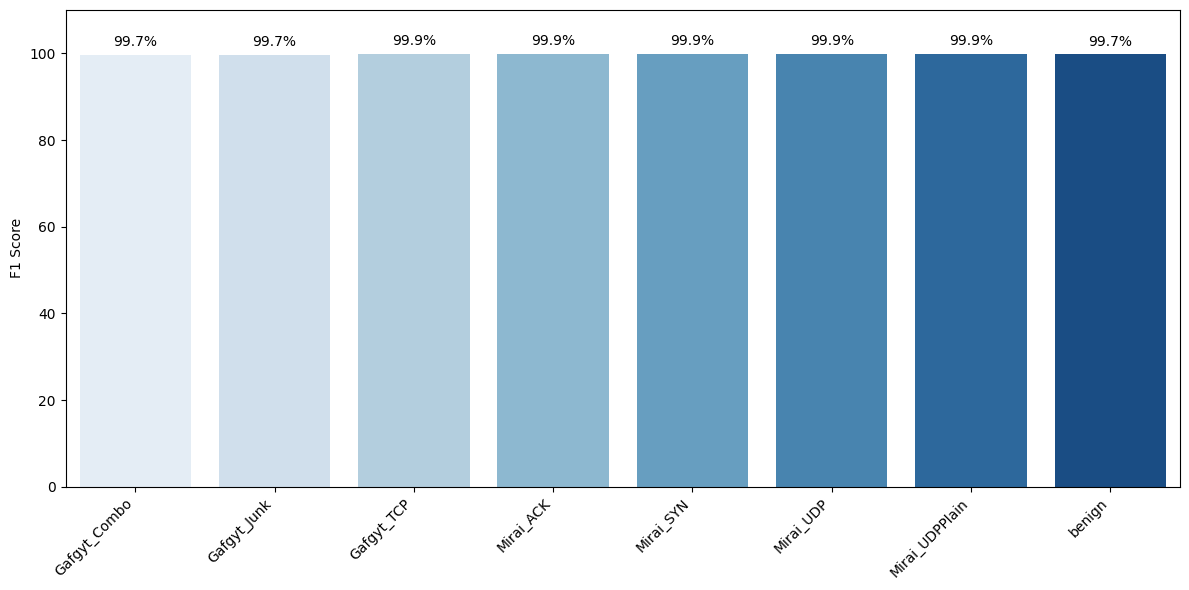

In [17]:


seen_report = classification_report(
    y_true_seen,
    y_pred_seen,
    output_dict=True,
    zero_division=0
)

# Keep only class rows (ignore averages) + EXCLUDE "Emerging"
seen_classes = [
    k for k in seen_report.keys()
    if k not in ['accuracy', 'macro avg', 'weighted avg', 'Emerging']
]

# Metric to show as % (recall)
seen_recall_pct = [seen_report[c]['f1-score'] * 100 for c in seen_classes]

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    x=seen_classes,
    y=seen_recall_pct,
    palette=sns.color_palette("Blues", n_colors=len(seen_classes))
)
plt.title("")
plt.ylabel("F1 Score")
plt.xlabel("")
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 110)  # headroom for labels

# Add % labels on top of bars
for p, val in zip(ax.patches, seen_recall_pct):
    ax.annotate(
        f"{val:.1f}%",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha="center",
        va="bottom",
        fontsize=10,
        xytext=(0, 4),
        textcoords="offset points"
    )

plt.tight_layout()
plt.savefig("seen_recall_bar_with_percent_no_emerging.png", dpi=300)
plt.show()

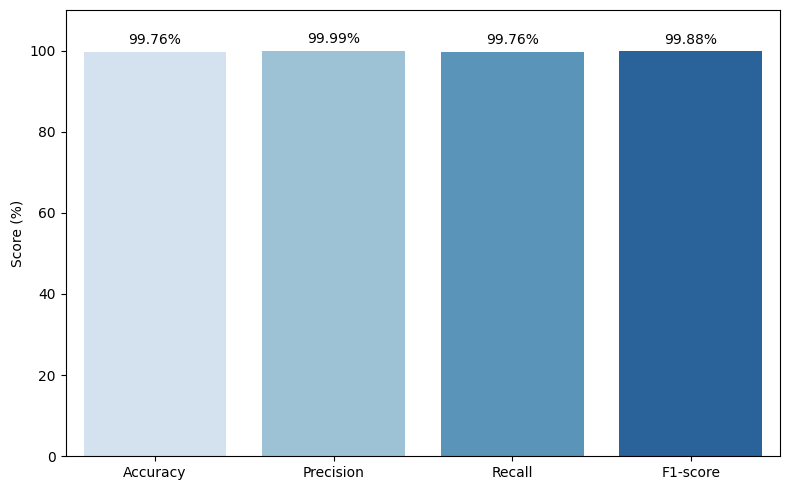

In [23]:
# ==========================================
# 4) Overall Metrics Visualization (Accuracy, Precision, Recall, F1)
# ==========================================
report_dict=seen_report
# Get overall metrics (use weighted avg for multi-class)
acc = report_dict["accuracy"] * 100
prec = report_dict["weighted avg"]["precision"] * 100
rec = report_dict["weighted avg"]["recall"] * 100
f1 = report_dict["weighted avg"]["f1-score"] * 100

overall_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score (%)": [acc, prec, rec, f1]
})

plt.figure(figsize=(8, 5))
ax_overall = sns.barplot(
    data=overall_df,
    x="Metric",
    y="Score (%)",
    palette=sns.color_palette("Blues", n_colors=len(overall_df))
)

plt.title("")
plt.ylabel("Score (%)")
plt.xlabel("")
plt.ylim(0, 110)

# Add values on top of bars
for container in ax_overall.containers:
    ax_overall.bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.savefig("overall_seen_metrics.png", dpi=300)
plt.show()


In [ ]:
data["label"].value_counts()

In [ ]:
len(data.columns)

In [ ]:
data['type'].value_counts()

In [ ]:
plt.savefig("Confusion_matrix.png")

In [38]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve , auc
from itertools import cycle


--- Generating ROC Curves ---


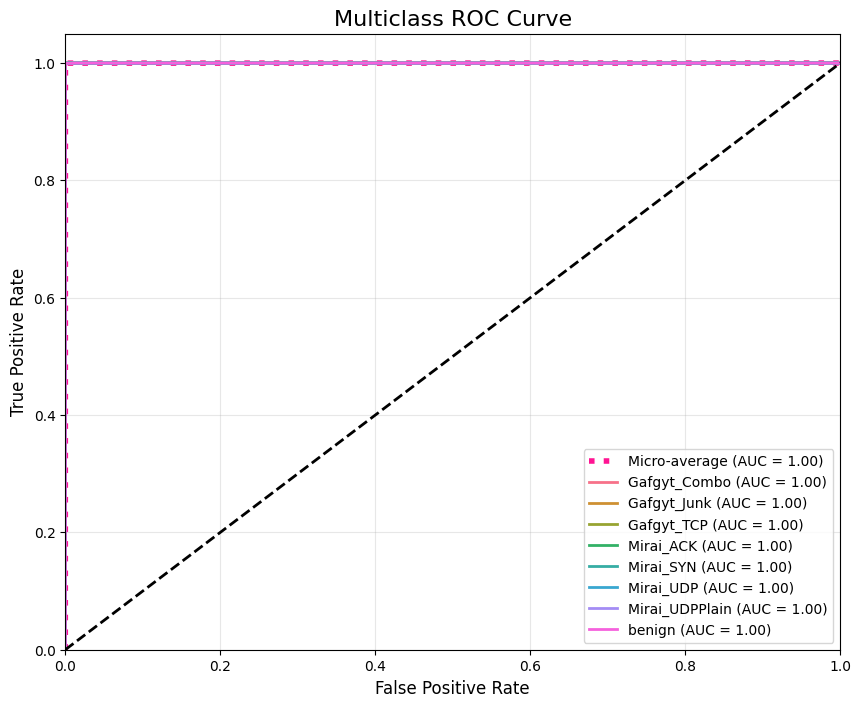


All charts generated and saved.


In [40]:
print("\n--- Generating ROC Curves ---")
# Filter test set to only include SEEN classes for valid ROC calculation
mask_seen = np.isin(y_test_final_str, SEEN_CLASSES)
y_test_seen_only = y_test_final_str[mask_seen]
X_test_seen_only = X_test_final[mask_seen] 

# Create a temporary loader
seen_ds = IoTDataset(X_test_seen_only, np.zeros(len(X_test_seen_only))) 
seen_loader = DataLoader(seen_ds, batch_size=CONFIG['batch_size'], shuffle=False)

# Get raw probabilities
probs_seen, _ = get_probabilities(model, seen_loader,'cuda') 

# Binarize labels
classes = list(le.classes_)
y_test_bin = label_binarize(y_test_seen_only, classes=classes)
n_classes = y_test_bin.shape[1]

# Plot
plt.figure(figsize=(10, 8))
fpr = dict()
tpr = dict()
roc_auc = dict()

# Calculate micro-average
fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), probs_seen.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

plt.plot(fpr["micro"], tpr["micro"],
         label='Micro-average (AUC = {0:0.2f})'.format(roc_auc["micro"]),
         color='deeppink', linestyle=':', linewidth=4)

# Plot each class
colors = cycle(sns.color_palette("husl", n_classes)) # Distinct colors for lines
for i, color in zip(range(n_classes), colors):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], probs_seen[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label='{0} (AUC = {1:0.2f})'.format(classes[i], roc_auc[i]))

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Multiclass ROC Curve', fontsize=16)
plt.legend(loc="lower right", fontsize=10)
plt.grid(alpha=0.3)
plt.savefig('/kaggle/working/multiclass_roc_curve.png', dpi=300)
plt.show()

print("\nAll charts generated and saved.")

## **Explainable Ai**

In [12]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import shap
from sklearn.preprocessing import StandardScaler

# --- 1. Define Model Architecture (Must match training exactly) ---
class CNNTransformerBiLSTM(nn.Module):
    def __init__(self, input_len, num_classes):
        super(CNNTransformerBiLSTM, self).__init__()
        # CNN
        self.conv1 = nn.Conv1d(in_channels=1, out_channels=64, kernel_size=3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool1d(kernel_size=2) 
        self.conv2 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        # Transformer
        encoder_layer = nn.TransformerEncoderLayer(d_model=128, nhead=4, dim_feedforward=128, dropout=0.1, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=1)
        # BiLSTM
        self.lstm = nn.LSTM(input_size=128, hidden_size=64, bidirectional=True, batch_first=True)
        # Classifier
        self.fc1 = nn.Linear(64*2, 64)
        self.dropout = nn.Dropout(0.3)
        self.fc_out = nn.Linear(64, num_classes)
        
    def forward(self, x):
        x = x.permute(0, 2, 1) 
        x = self.relu(self.conv1(x))
        x = self.pool(x)
        x = self.relu(self.conv2(x)) 
        x = x.permute(0, 2, 1) 
        x = self.transformer(x)
        _, (h_n, _) = self.lstm(x)
        x = torch.cat((h_n[-2,:,:], h_n[-1,:,:]), dim=1)
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc_out(x)
        return x

# --- 2. Configuration & Setup ---
CONFIG = {
    'model_path': '/kaggle/working/gtrs_final_model.pth',
    'input_shape': (46, 1), 
    'num_classes': 8 
}

SEEN_CLASSES = ['Mirai_UDP', 'Mirai_SYN', 'Mirai_ACK', 'Gafgyt_TCP', 'Mirai_UDPPlain', 'Gafgyt_Combo', 'benign', 'Gafgyt_Junk']

# Explicit Feature Names from CICIoT2023 Dataset
FEATURE_NAMES = list(columns.columns)

# Validate feature count matches config
if len(FEATURE_NAMES) != CONFIG['input_shape'][0]:
    print(f"Warning: Feature name list length ({len(FEATURE_NAMES)}) does not match input shape ({CONFIG['input_shape'][0]}). Truncating or padding.")
    if len(FEATURE_NAMES) > CONFIG['input_shape'][0]:
        FEATURE_NAMES = FEATURE_NAMES[:CONFIG['input_shape'][0]]
    else:
        FEATURE_NAMES += [f"Feature_{i}" for i in range(len(FEATURE_NAMES), CONFIG['input_shape'][0])]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- 3. Load Model ---
print("Loading model...")
model = CNNTransformerBiLSTM(input_len=CONFIG['input_shape'][0], num_classes=CONFIG['num_classes']).to(device)
try:
    model.load_state_dict(torch.load(CONFIG['model_path'], map_location=device))
    print("Model loaded successfully.")
except FileNotFoundError:
    print("Warning: Saved model not found. Using initialized weights for demonstration.")

model.eval()

# --- 4. Prepare SHAP Data (KernelExplainer Setup) ---
print("Initializing SHAP KernelExplainer...")

# Create background data for KernelExplainer
# We generate a synthetic background (replace with X_train sample in real usage)
background_data_np = np.random.rand(50, CONFIG['input_shape'][0]).astype(np.float32)

# Define prediction function for KernelExplainer
def predict_proba_shap(data_numpy):
    data_tensor = torch.tensor(data_numpy, dtype=torch.float32).unsqueeze(2).to(device)
    with torch.no_grad():
        logits = model(data_tensor)
        probs = torch.softmax(logits, dim=1)
    return probs.cpu().numpy()

# Initialize KernelExplainer
explainer = shap.KernelExplainer(predict_proba_shap, background_data_np)

# --- 5. Compute SHAP Values ---
print("Computing SHAP values for test samples...")
# Generate dummy test data for demonstration (Replace with X_test in real usage)
# We create 50 random samples to ensure we likely hit different classes
test_data_np = np.random.rand(50, CONFIG['input_shape'][0]).astype(np.float32) 

# Run KernelExplainer
shap_values = explainer.shap_values(test_data_np, nsamples=100)

# --- 6. Visualizations (Per-Class Analysis) ---

# A. Global Summary Plot
print("Generating Global Summary Plot...")
plt.figure()
shap.summary_plot(shap_values, test_data_np, feature_names=FEATURE_NAMES, class_names=SEEN_CLASSES, show=False)
plt.title("SHAP Summary Plot (Global Explanation)")
plt.tight_layout()
plt.savefig('shap_summary_plot_global.png')
plt.close()
print("Saved 'shap_summary_plot_global.png'")

# B. Per-Class Explanations (Decision & Waterfall)
print("\nGenerating Per-Class Explanation Plots...")

# Get predictions to find representative samples for each class
test_probs = predict_proba_shap(test_data_np)
test_preds = np.argmax(test_probs, axis=1)

for class_idx, class_name in enumerate(SEEN_CLASSES):
    # Find a sample predicted as this class
    sample_indices = np.where(test_preds == class_idx)[0]
    
    if len(sample_indices) == 0:
        print(f"Skipping Class '{class_name}' - No samples predicted as this class in test subset.")
        continue
        
    sample_idx = sample_indices[0] # Pick the first sample found for this class
    print(f"--> Generating plots for Class: {class_name} (Sample Index: {sample_idx})")
    
    # 1. Decision Plot
    # Shows the "path" of feature contributions from base value to final prediction
    plt.figure()
    base_val = explainer.expected_value[class_idx]
    
    shap.decision_plot(
        base_val, 
        shap_values[class_idx][sample_idx], 
        test_data_np[sample_idx], 
        feature_names=FEATURE_NAMES,
        show=False,
        title=f"Decision Plot: {class_name}"
    )
    plt.tight_layout()
    plt.savefig(f'shap_decision_plot_{class_name}.png')
    plt.close()
    
    # 2. Waterfall Plot
    # Shows detailed positive/negative contributions for top features
    plt.figure()
    try:
        # Create Explanation object required for waterfall plot
        exp = shap.Explanation(
            values=shap_values[class_idx][sample_idx],
            base_values=base_val,
            data=test_data_np[sample_idx],
            feature_names=FEATURE_NAMES
        )
        shap.waterfall_plot(exp, show=False)
        plt.title(f"Waterfall Plot: {class_name}")
        plt.tight_layout()
        plt.savefig(f'shap_waterfall_plot_{class_name}.png')
        plt.close()
    except Exception as e:
        print(f"   Waterfall plot failed for {class_name}: {e}")

print("\nSHAP analysis complete. Check generated files for each class.")

Loading model...
Model loaded successfully.
Initializing SHAP KernelExplainer...
Computing SHAP values for test samples...


  0%|          | 0/50 [00:00<?, ?it/s]

Generating Global Summary Plot...


The figure layout has changed to tight


Saved 'shap_summary_plot_global.png'

Generating Per-Class Explanation Plots...
Skipping Class 'Mirai_UDP' - No samples predicted as this class in test subset.
Skipping Class 'Mirai_SYN' - No samples predicted as this class in test subset.
Skipping Class 'Mirai_ACK' - No samples predicted as this class in test subset.
Skipping Class 'Gafgyt_TCP' - No samples predicted as this class in test subset.
Skipping Class 'Mirai_UDPPlain' - No samples predicted as this class in test subset.
--> Generating plots for Class: Gafgyt_Combo (Sample Index: 0)
--> Generating plots for Class: benign (Sample Index: 8)
Skipping Class 'Gafgyt_Junk' - No samples predicted as this class in test subset.

SHAP analysis complete. Check generated files for each class.


In [16]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import shap
from sklearn.preprocessing import StandardScaler
import lime

# --- 1. Define Model Architecture (Must match training exactly) ---
class CNNTransformerBiLSTM(nn.Module):
    def __init__(self, input_len, num_classes):
        super(CNNTransformerBiLSTM, self).__init__()
        # CNN
        self.conv1 = nn.Conv1d(in_channels=1, out_channels=64, kernel_size=3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool1d(kernel_size=2) 
        self.conv2 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        # Transformer
        encoder_layer = nn.TransformerEncoderLayer(d_model=128, nhead=4, dim_feedforward=128, dropout=0.1, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=1)
        # BiLSTM
        self.lstm = nn.LSTM(input_size=128, hidden_size=64, bidirectional=True, batch_first=True)
        # Classifier
        self.fc1 = nn.Linear(64*2, 64)
        self.dropout = nn.Dropout(0.3)
        self.fc_out = nn.Linear(64, num_classes)
        
    def forward(self, x):
        x = x.permute(0, 2, 1) 
        x = self.relu(self.conv1(x))
        x = self.pool(x)
        x = self.relu(self.conv2(x)) 
        x = x.permute(0, 2, 1) 
        x = self.transformer(x)
        _, (h_n, _) = self.lstm(x)
        x = torch.cat((h_n[-2,:,:], h_n[-1,:,:]), dim=1)
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc_out(x)
        return x

# --- 2. Configuration & Setup ---
CONFIG = {
    'model_path': '/kaggle/working/gtrs_final_model.pth',
    'input_shape': (46, 1), 
    'num_classes': 8 
}

SEEN_CLASSES = ['Mirai_UDP', 'Mirai_SYN', 'Mirai_ACK', 'Gafgyt_TCP', 'Mirai_UDPPlain', 'Gafgyt_Combo', 'benign', 'Gafgyt_Junk']

# Explicit Feature Names from CICIoT2023 Dataset
FEATURE_NAMES = list(columns.columns)
# Validate feature count matches config
if len(FEATURE_NAMES) != CONFIG['input_shape'][0]:
    print(f"Warning: Feature name list length ({len(FEATURE_NAMES)}) does not match input shape ({CONFIG['input_shape'][0]}). Truncating or padding.")
    if len(FEATURE_NAMES) > CONFIG['input_shape'][0]:
        FEATURE_NAMES = FEATURE_NAMES[:CONFIG['input_shape'][0]]
    else:
        FEATURE_NAMES += [f"Feature_{i}" for i in range(len(FEATURE_NAMES), CONFIG['input_shape'][0])]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- 3. Load Model ---
print("Loading model...")
model = CNNTransformerBiLSTM(input_len=CONFIG['input_shape'][0], num_classes=CONFIG['num_classes']).to(device)
try:
    model.load_state_dict(torch.load(CONFIG['model_path'], map_location=device))
    print("Model loaded successfully.")
except FileNotFoundError:
    print("Warning: Saved model not found. Using initialized weights for demonstration.")

model.eval()

# --- 4. Prepare Background Data ---
print("Preparing background data...")
# We generate a synthetic background (replace with X_train sample in real usage)
background_data_np = np.random.rand(50, CONFIG['input_shape'][0]).astype(np.float32)

# Define prediction function for KernelExplainer/LIME
def predict_proba_shap(data_numpy):
    data_tensor = torch.tensor(data_numpy, dtype=torch.float32).unsqueeze(2).to(device)
    with torch.no_grad():
        logits = model(data_tensor)
        probs = torch.softmax(logits, dim=1)
    return probs.cpu().numpy()

# --- 5. LIME Explanations (Per-Class) ---
print("\n--- Initializing LIME Explainer ---")
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=background_data_np, # Ideally use X_train
    feature_names=FEATURE_NAMES,
    class_names=SEEN_CLASSES,
    mode='classification',
    discretize_continuous=True
)

# Generate dummy test data for demonstration (Replace with X_test in real usage)
test_data_np = np.random.rand(50, CONFIG['input_shape'][0]).astype(np.float32) 

# Get predictions to find representative samples for each class
test_probs = predict_proba_shap(test_data_np)
test_preds = np.argmax(test_probs, axis=1)

print("\nGenerating Per-Class LIME Explanations...")

for class_idx, class_name in enumerate(SEEN_CLASSES):
    # Find a sample predicted as this class
    sample_indices = np.where(test_preds == class_idx)[0]
    
    if len(sample_indices) == 0:
        print(f"Skipping Class '{class_name}' - No samples predicted as this class in test subset.")
        continue
        
    sample_idx = sample_indices[0] # Pick the first sample found for this class
    print(f"--> Generating LIME plots for Class: {class_name} (Sample Index: {sample_idx})")
    
    # Generate LIME explanation
    # num_features=10: Show top 10 contributing features
    exp = lime_explainer.explain_instance(
        data_row=test_data_np[sample_idx], 
        predict_fn=predict_proba_shap, 
        num_features=10, 
        top_labels=1
    )
    
    # 1. Save Explanation as HTML (Interactive)
    html_filename = f'lime_explanation_{class_name}.html'
    exp.save_to_file(html_filename)
    print(f"   Saved HTML explanation to {html_filename}")
    
    # 2. Generate Feature Contribution Plot (Right side of Paper Fig 12)
    fig = exp.as_pyplot_figure(label=class_idx)
    plt.title(f"LIME Feature Contributions: {class_name}")
    plt.tight_layout()
    plt.savefig(f'lime_feature_plot_{class_name}.png')
    plt.close()
    
    # 3. Generate Prediction Probabilities Plot (Left side of Paper Fig 12)
    # Get probs for this specific sample
    sample_probs = test_probs[sample_idx]
    
    plt.figure(figsize=(6, 4))
    # Create horizontal bar chart
    y_pos = np.arange(len(SEEN_CLASSES))
    plt.barh(y_pos, sample_probs, align='center', color='skyblue')
    plt.yticks(y_pos, SEEN_CLASSES)
    plt.xlabel('Probability')
    plt.title(f'Prediction Probabilities (Sample {sample_idx})')
    plt.xlim(0, 1.05) # Probability is 0-1
    
    # Add value labels
    for i, v in enumerate(sample_probs):
        plt.text(v + 0.01, i, f"{v:.2f}", color='black', va='center')
        
    plt.tight_layout()
    plt.savefig(f'lime_probability_plot_{class_name}.png')
    plt.close()

print("\nLIME analysis complete. Check generated HTML and PNG files.")

# --- 6. SHAP Visualizations (Existing code) ---
print("\n--- Starting SHAP Analysis ---")
explainer = shap.KernelExplainer(predict_proba_shap, background_data_np)
shap_values = explainer.shap_values(test_data_np, nsamples=100)

# A. Global Summary Plot
print("Generating Global Summary Plot...")
plt.figure()
shap.summary_plot(shap_values, test_data_np, feature_names=FEATURE_NAMES, class_names=SEEN_CLASSES, show=False)
plt.title("SHAP Summary Plot (Global Explanation)")
plt.tight_layout()
plt.savefig('shap_summary_plot_global.png')
plt.close()
print("Saved 'shap_summary_plot_global.png'")

# B. Per-Class SHAP Plots
print("\nGenerating Per-Class SHAP Explanation Plots...")
for class_idx, class_name in enumerate(SEEN_CLASSES):
    sample_indices = np.where(test_preds == class_idx)[0]
    if len(sample_indices) == 0: continue
    sample_idx = sample_indices[0]
    
    # Decision Plot
    plt.figure()
    base_val = explainer.expected_value[class_idx]
    shap.decision_plot(
        base_val, 
        shap_values[class_idx][sample_idx], 
        test_data_np[sample_idx], 
        feature_names=FEATURE_NAMES,
        show=False,
        title=f"Decision Plot: {class_name}"
    )
    plt.tight_layout()
    plt.savefig(f'shap_decision_plot_{class_name}.png')
    plt.close()
    
    # Waterfall Plot
    plt.figure()
    try:
        exp = shap.Explanation(
            values=shap_values[class_idx][sample_idx],
            base_values=base_val,
            data=test_data_np[sample_idx],
            feature_names=FEATURE_NAMES
        )
        shap.waterfall_plot(exp, show=False)
        plt.title(f"Waterfall Plot: {class_name}")
        plt.tight_layout()
        plt.savefig(f'shap_waterfall_plot_{class_name}.png')
        plt.close()
    except Exception as e:
        print(f"   Waterfall plot failed for {class_name}: {e}")

print("\nAll Explainable AI charts generated.")

Loading model...
Model loaded successfully.
Preparing background data...

--- Initializing LIME Explainer ---

Generating Per-Class LIME Explanations...
Skipping Class 'Mirai_UDP' - No samples predicted as this class in test subset.
Skipping Class 'Mirai_SYN' - No samples predicted as this class in test subset.
Skipping Class 'Mirai_ACK' - No samples predicted as this class in test subset.
Skipping Class 'Gafgyt_TCP' - No samples predicted as this class in test subset.
Skipping Class 'Mirai_UDPPlain' - No samples predicted as this class in test subset.
--> Generating LIME plots for Class: Gafgyt_Combo (Sample Index: 1)
   Saved HTML explanation to lime_explanation_Gafgyt_Combo.html
--> Generating LIME plots for Class: benign (Sample Index: 0)
   Saved HTML explanation to lime_explanation_benign.html
Skipping Class 'Gafgyt_Junk' - No samples predicted as this class in test subset.

LIME analysis complete. Check generated HTML and PNG files.

--- Starting SHAP Analysis ---


  0%|          | 0/50 [00:00<?, ?it/s]

Generating Global Summary Plot...


The figure layout has changed to tight


Saved 'shap_summary_plot_global.png'

Generating Per-Class SHAP Explanation Plots...

All Explainable AI charts generated.
